In [17]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
visa_df =pd.read_csv(r"C:\Naresh IT\Data_files\Visadataset.csv")
visa_df

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
1,EZYV02,Asia,Master's,Y,N,2412,2002,Northeast,83425.6500,Year,Y,Certified
2,EZYV03,Asia,Bachelor's,N,Y,44444,2008,West,122996.8600,Year,Y,Denied
3,EZYV04,Asia,Bachelor's,N,N,98,1897,West,83434.0300,Year,Y,Denied
4,EZYV05,Africa,Master's,Y,N,1082,2005,South,149907.3900,Year,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...,...
25475,EZYV25476,Asia,Bachelor's,Y,Y,2601,2008,South,77092.5700,Year,Y,Certified
25476,EZYV25477,Asia,High School,Y,N,3274,2006,Northeast,279174.7900,Year,Y,Certified
25477,EZYV25478,Asia,Master's,Y,N,1121,1910,South,146298.8500,Year,N,Certified
25478,EZYV25479,Asia,Master's,Y,Y,1918,1887,West,86154.7700,Year,Y,Certified


In [18]:
num = visa_df.select_dtypes(exclude=['string']).columns # for now after dtypes  old string stored in objects not a option now espicly dtyppes string to store text beofre need  to wrappedstring in objects
cat = visa_df.select_dtypes(include=['object','string']).columns  # for news version we stred the categircal  in strings as objects previous tet we store string in  objcets 


- Old Pandas (before v2.0) → all text/categorical data was stored as object dtype. That was the only option, so strings lived inside object.

- New Pandas (v2.0 and later) → they introduced a dedicated string dtype. This is the modern, preferred way to store text because it’s more consistent and avoids mixing with other Python objects.

- Right now → Pandas still lets object catch string columns for backward compatibility, but it warns you that in the future (Pandas 3.x) this will stop

In [19]:
num

Index(['no_of_employees', 'yr_of_estab', 'prevailing_wage'], dtype='str')

In [20]:
cat

Index(['case_id', 'continent', 'education_of_employee', 'has_job_experience',
       'requires_job_training', 'region_of_employment', 'unit_of_wage',
       'full_time_position', 'case_status'],
      dtype='str')

**prevailing_wage**

In [21]:
visa_df['prevailing_wage']

0           592.2029
1         83425.6500
2        122996.8600
3         83434.0300
4        149907.3900
            ...     
25475     77092.5700
25476    279174.7900
25477    146298.8500
25478     86154.7700
25479     70876.9100
Name: prevailing_wage, Length: 25480, dtype: float64

In [22]:
- count
- min
- 25p 
- 50p
- mean
- median
- 75p 
-max


SyntaxError: invalid decimal literal (1548594596.py, line 3)

In [23]:
pwage = visa_df['prevailing_wage']


In [24]:
l=[pwage.min(),
   pwage.max(),
   round(np.percentile(pwage,25),2),
   round(np.percentile(pwage,75)),  
   round(pwage.mean(),2),
   round(pwage.median(),2), # np.percentile(pwage,50) are same  as median
   round(np.percentile(pwage,50),2),
   round(np.percentile(pwage,75)),
   pwage.count()]
ID=['min','Max','25p','75','mean','median','50','75','count']
pd.DataFrame(l,columns=['prevailing_wage'],index=ID)


,prevailing_wage
min,2.1367
Max,319210.2700
25p,34015.4800
75,107736.0000
mean,74455.8100
median,70308.2100
50,70308.2100
75,107736.0000
count,25480.0000


In [25]:
Count = pwage.count()
Min = pwage.min()
Mean= pwage.mean()
Median = pwage.median()
Max = pwage.max()
P_25 = round(np.percentile(pwage,25),2)
P_75 =round(np.percentile(pwage,75),2)
P_50 = round(np.percentile(pwage,50),2)
l = [Count,Min,Mean,Median,Max,P_25,P_75,P_50]
ID  = ['Count','Min','Mean','Median','Max','P_25','P_75','p_50']
pd.DataFrame(l,columns=['prevailing_wage'],
             index=ID)

,prevailing_wage
Count,25480.000000
Min,2.136700
Mean,74455.814592
Median,70308.210000
Max,319210.270000
P_25,34015.480000
P_75,107735.510000
p_50,70308.210000


In [26]:
uwage =  visa_df['unit_of_wage']
Count = pwage.count()
Min = pwage.min()
Mean= pwage.mean()
Median = pwage.median()
Max = pwage.max()
P_25 = round(np.percentile(pwage,25),2)
P_75 =round(np.percentile(pwage,75),2)
P_50 = round(np.percentile(pwage,50),2)
l = [Count,Min,Mean,Median,Max,P_25,P_75,P_50]
ID  = ['Count','Min','Mean','Median','Max','P_25','P_75','p_50']
pd.DataFrame(l,columns=['unit_of_wage'],
             index=ID)

,unit_of_wage
Count,25480.000000
Min,2.136700
Mean,74455.814592
Median,70308.210000
Max,319210.270000
P_25,34015.480000
P_75,107735.510000
p_50,70308.210000


In [27]:
final_list=[]
for i in num:
    
    Count = visa_df[i].count()
    Min = visa_df[i].min()
    Mean= round(visa_df[i].mean(),2)
    Median = round(visa_df[i].median(),2)
    Max = visa_df[i].max()
    P_25 = round(np.percentile(visa_df[i],25),2)
    P_75 =round(np.percentile(visa_df[i],75),2)
    P_50 = round(np.percentile(visa_df[i],50),2)
    l = [Count,Min,Mean,Median,Max,P_25,P_75,P_50]
    final_list.append(l)

df=pd.DataFrame()
for i in final_list:
    df[f'{i}']=i
df.columns=num
df.index=ID
df

,no_of_employees,yr_of_estab,prevailing_wage
Count,25480.00,25480.00,25480.0000
Min,-26.00,1800.00,2.1367
Mean,5667.04,1979.41,74455.8100
Median,2109.00,1997.00,70308.2100
Max,602069.00,2016.00,319210.2700
P_25,1022.00,1976.00,34015.4800
P_75,3504.00,2005.00,107735.5100
p_50,2109.00,1997.00,70308.2100


**describe Function**

In [28]:
visa_df.describe()

,no_of_employees,yr_of_estab,prevailing_wage
count,25480.000000,25480.000000,25480.000000
mean,5667.043210,1979.409929,74455.814592
std,22877.928848,42.366929,52815.942327
min,-26.000000,1800.000000,2.136700
25%,1022.000000,1976.000000,34015.480000
50%,2109.000000,1997.000000,70308.210000
75%,3504.000000,2005.000000,107735.512500
max,602069.000000,2016.000000,319210.270000


**Percentile**

In [29]:
wage_data = visa_df['prevailing_wage']
np.percentile(wage_data,25)  #  it  mean  34015.479999999996 greather than 25%appliacnts  wage
#25% of number of applicants have wagers lower than 34015.479999999996
# wage mean money paid to labours and worker 

np.float64(34015.479999999996)

- it  mean  34015.479999999996 greather than 25%appliacnts  wage
- 25% of number of applicants have wagers lower than 34015.479999999996
- wage mean money paid to labours and worker 
- 25%(25480) has salary less than 34015.479999999996
- 6370 applicants has salary less than 34015.479999999996

In [30]:
wage_data=visa_df['prevailing_wage']
con=wage_data<np.percentile(wage_data,25)
np.sum(con)  # it give count of 25 salary less than employees how many

np.int64(6370)

In [31]:
visa_df[con]  # it showw data

,case_id,continent,education_of_employee,has_job_experience,requires_job_training,no_of_employees,yr_of_estab,region_of_employment,prevailing_wage,unit_of_wage,full_time_position,case_status
0,EZYV01,Asia,High School,N,N,14513,2007,West,592.2029,Hour,Y,Denied
7,EZYV08,North America,Bachelor's,Y,N,3035,1924,West,418.2298,Hour,Y,Denied
12,EZYV13,Asia,Bachelor's,Y,N,123876,1963,Northeast,28663.0500,Year,Y,Certified
16,EZYV17,Europe,Master's,Y,N,76638,1991,Midwest,3706.7900,Year,Y,Certified
17,EZYV18,Asia,Master's,Y,N,2747,2001,West,16132.6100,Year,Y,Certified
...,...,...,...,...,...,...,...,...,...,...,...,...
25461,EZYV25462,Asia,Master's,Y,N,2861,2004,West,54.9196,Hour,Y,Denied
25465,EZYV25466,North America,High School,N,N,2577,1995,South,481.2238,Hour,Y,Certified
25466,EZYV25467,Europe,Bachelor's,Y,N,1938,2005,West,6973.4000,Year,Y,Denied
25470,EZYV25471,North America,Master's,Y,N,2272,1970,Northeast,516.4101,Hour,Y,Certified


**Emperical Rule**

In [32]:
# - 68% of data Available between  u-1*sd to u+1*sd
# - step-1: calculate mean of wage:mean  #mean = 74455
wage_data=visa_df['prevailing_wage']
mean=wage_data.mean()
mean
# - step-2: calculate sd of wage: #sd:52815  
sd = wage_data.std()
sd
# - step-3: lb=mean-1*sd lowerbond  #21640
lb = mean-1*sd
lb

# - step-4: ub=mean+1*sd  upperbond  #127270
ub = mean+1*sd 
ub
# - step-5: con1=wage_data>lb
con1 = wage_data>lb

# - step 6: cond2=wage_data<ub
con2=wage_data<ub 

# -step:7 con1 and con2
con = con1 & con2

# - step:8 : np.sum()  #17170
np.sum(con)
# - steepp 9: 68%(25480) : 
np.sum(con)==68*(25480)/100
   #false mean not normal istrbution

np.False_

In [33]:
wage_data=visa_df['prevailing_wage']
mean=wage_data.mean()
sd = wage_data.std()
lb = mean-1*sd
ub = mean+1*sd 
con1 = wage_data>lb
con2=wage_data<ub 
con = con1 & con2
np.sum(con),99*(25480)/100


(np.int64(17171), 25225.2)

In [34]:
np.sum(con)==68*(25480)/100

np.False_

In [35]:
np.sum(con)

np.int64(17171)

**Conclusion is wage data not follow a normal distribution**

**histogram**

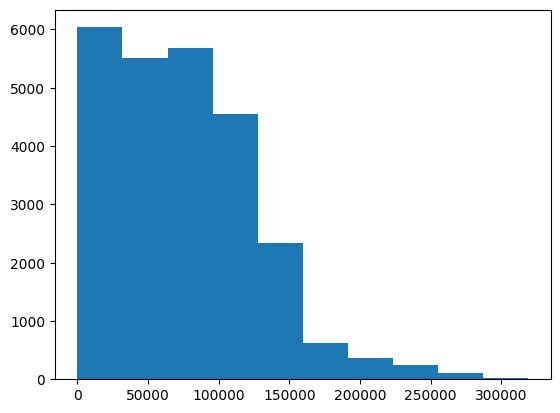

In [36]:
wage_data=visa_df['prevailing_wage']
plt.hist(wage_data)
plt.show()

**box plot**

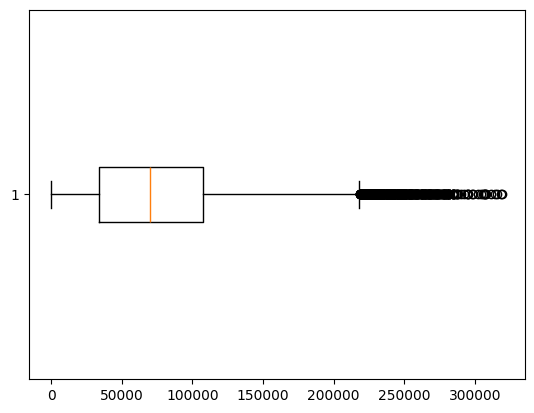

In [37]:
wage_data = visa_df['prevailing_wage']
plt.boxplot(wage_data,vert=False)   # vert = true mean verttical or false meanhoriznonal 
plt.show()

***how  many outlier***

In [38]:
q1 =  visa_df['prevailing_wage'].quantile(0.25)
q1

np.float64(34015.479999999996)

In [39]:
q2 = visa_df['prevailing_wage'].quantile(0.50)
q2


np.float64(70308.20999999999)

In [40]:
q3=  visa_df['prevailing_wage'].quantile(0.75)
q3

np.float64(107735.51250000001)

In [41]:
IQR = q3-q1
IQR
lb=q1-1.*IQR
lb
ub=q3-1.5*IQR
ub
con1 = wage_data<lb
con1
cond2 =wage_data>ub
cond2
con = con1|cond2  #| is  a or 
np.sum(con)


np.int64(25480)

In [42]:
#above my try 

In [43]:
wage_data = visa_df['prevailing_wage']
q1 = np.percentile(wage_data,25)
q2 =  np.percentile(wage_data,50)
q3 =  np.percentile(wage_data,75)
IQR = q3-q1 #Interquartile Range (IQR) 
lb = q1-1.5*IQR
ub = q3+ 1.5*IQR
con1 = wage_data<lb 
con2 = wage_data>ub
con = con1 | con2 # or when one is condition true retunr true 
np.sum(con)  #427 are outlier 

np.int64(427)

In [44]:
wage_outliers = wage_data[con].values

**fill the outlier with median**

In [45]:
wage_data[con].values  # it provide wage data 


array([220081.73, 225569.73, 247393.01, 269321.68, 219529.62, 232227.33,
       238691.32, 220448.17, 230750.48, 235339.91, 232680.65, 256261.78,
       262189.  , 250510.67, 218554.78, 256205.38, 221944.22, 229950.7 ,
       222628.84, 229819.69, 233641.72, 274019.43, 218982.83, 230984.28,
       223128.23, 246705.  , 240266.34, 226090.72, 231949.27, 254604.08,
       288318.91, 244457.48, 242146.48, 247545.23, 234139.17, 231834.72,
       222730.57, 239773.63, 220553.95, 237539.32, 266440.49, 277281.01,
       275627.59, 249291.12, 292106.59, 234012.11, 247009.24, 267726.09,
       222098.09, 280661.13, 277984.52, 262852.71, 263877.21, 230916.64,
       264760.64, 267868.56, 222221.67, 242406.32, 276894.08, 281832.93,
       221033.57, 258292.84, 223492.85, 245418.67, 250289.08, 271344.69,
       252825.11, 230843.7 , 253668.86, 245819.17, 239465.3 , 236316.36,
       225268.13, 228941.33, 306021.96, 228074.25, 270799.93, 221982.69,
       256903.7 , 242813.07, 253111.05, 268440.33, 

In [46]:
# l = [1,2,3,4,5,6,7,8,9,10]
# l1 = [5,8,10]
# l = [1,,3,4,50,6,7,50,9,50]



In [52]:
l =[]
for i in wage_data:
    if i in wage_outliers:
        l.append(q2)
    else:
        l.append(i)
visa_df['wages_q2']=l



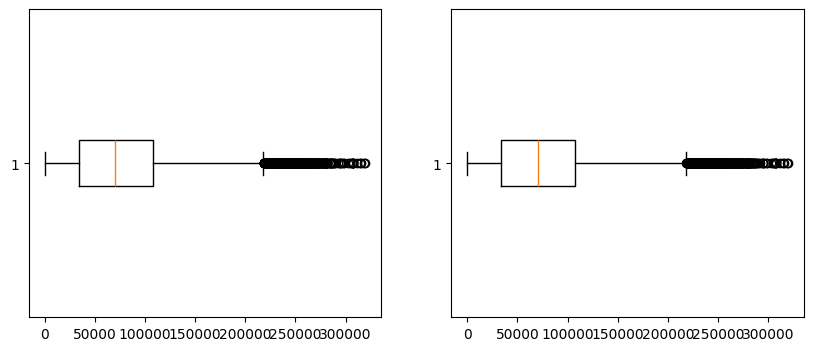

In [54]:
wage_data=visa_df['prevailing_wage']
wage_data_q2=visa_df['wages_q2']
plt.figure(figsize=(10,4))
plt.subplot(1,2,1).boxplot(wage_data,vert=False)
plt.subplot(1,2,2).boxplot(wage_data,vert=False)
plt.show()



In [ ]:
visa_df → your DataFrame.

'wages_q2' → a new column name (doesn’t exist until you assign it).

l → the list you built earlier in your loop (where you replaced outliers with Q2 or kept the original value).

In [ ]:
Capping 

- we can flll outleir whcih is less than 25p with 25pvalue '
- we can fill outleir wihcih is less than 75p with 75pvalue is q3 with in less than 75

In [57]:
wage_data = visa_df['prevailing_wage']
q1 = np.percentile(wage_data,25)
q2 =  np.percentile(wage_data,50)
q3 =  np.percentile(wage_data,75)
IQR = q3-q1 #Interquartile Range (IQR) 
lb = q1-1.5*IQR
ub = q3+ 1.5*IQR
visa_df['wage_data_cap']=wage_data.clip(lb,ub)
visa_df['wage_data_cap']

0           592.20290
1         83425.65000
2        122996.86000
3         83434.03000
4        149907.39000
             ...     
25475     77092.57000
25476    218315.56125
25477    146298.85000
25478     86154.77000
25479     70876.91000
Name: wage_data_cap, Length: 25480, dtype: float64